# 05 Feature Engineering and Chronological Split



In [2]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = "../reports/figures/"
RAW = "../data/raw/Dataset.xlsx"
from src.cleaning import TARGET_COL
from src.preprocessing import (build_features, chronological_split, expanding_window_folds, split_info,
                               write_data_dictionary, CHANNEL_NAMES, HIGH_PROMO_PCT, HIGH_HOLIDAY_COUNT)
from src.validation import validate_features

## What notebook 04 means for the features

| Finding in notebook 04 | Feature decision |
|---|---|
| Spend of earlier months still relates to revenue, and radio peaks at a lag of 2 months | Spend lagged by 1 and 2 months for each channel |
| A log fit is slightly better only for Google Search, YouTube and outdoor | Log spend for each channel is created as an option; the model decides whether to use it |
| Revenue peaks in April and December, and holidays matter | Month, quarter, sine and cosine of the month, and a high-holiday flag |
| Months with a promotion of at least 15% sell more | High-promotion flag |
| Inflation, price index and time move together | Kept as separate columns, but marked as collinear in the data dictionary |
| Channel mix is almost constant | Spend shares are created to describe the mix |
| Funnel counts are results of spend | Efficiency columns (click rate, cost per click, ROAS and so on) are created for the dashboard and marked as excluded from modelling |

Scaling, adstock and saturation are not applied here. They have parameters that the modelling team has to estimate, and any scaler must be fitted on the training data only.

In [3]:
clean = pd.read_csv("../data/processed/mmm_cleaned.csv", parse_dates=["month"])
feats = build_features(clean)
new_cols = [c for c in feats.columns if c not in clean.columns]
print(f"{clean.shape[1]} cleaned columns, {feats.shape[1]} columns after feature engineering ({len(new_cols)} new)")
new_cols

22 cleaned columns, 66 columns after feature engineering (44 new)


['year',
 'month_num',
 'quarter',
 'time_index',
 'month_sin',
 'month_cos',
 'tv_share',
 'log_tv_spend',
 'facebook_instagram_share',
 'log_facebook_instagram_spend',
 'google_search_share',
 'log_google_search_spend',
 'youtube_share',
 'log_youtube_spend',
 'radio_share',
 'log_radio_spend',
 'outdoor_share',
 'log_outdoor_spend',
 'log_total_ad_spend',
 'spend_rolling3_mean',
 'tv_spend_lag1',
 'facebook_instagram_spend_lag1',
 'google_search_spend_lag1',
 'youtube_spend_lag1',
 'radio_spend_lag1',
 'outdoor_spend_lag1',
 'tv_spend_lag2',
 'facebook_instagram_spend_lag2',
 'google_search_spend_lag2',
 'youtube_spend_lag2',
 'radio_spend_lag2',
 'outdoor_spend_lag2',
 'ctr',
 'cvr',
 'cpm_lkr',
 'cpc_lkr',
 'cost_per_conversion_lkr',
 'avg_unit_revenue_lkr',
 'roas_blended',
 'high_promo_flag',
 'high_holiday_flag',
 'revenue_real_lkr',
 'fx_mom_change_pct',
 'revenue_mom_growth_pct']

## Feature groups

| Group | Columns | Purpose |
|---|---|---|
| Time | `year`, `month_num`, `quarter`, `time_index`, `month_sin`, `month_cos` | trend and smooth seasonality |
| Spend shape | `<channel>_share`, `log_<channel>_spend`, `log_total_ad_spend`, `spend_rolling3_mean` | channel mix, concave transform, smoothing |
| Lags | `<channel>_spend_lag1`, `<channel>_spend_lag2` | delayed effect, earlier months only |
| Efficiency | `ctr`, `cvr`, `cpm_lkr`, `cpc_lkr`, `cost_per_conversion_lkr`, `avg_unit_revenue_lkr`, `roas_blended` | dashboard and diagnostics |
| External | `high_promo_flag`, `high_holiday_flag`, `revenue_real_lkr`, `fx_mom_change_pct`, `revenue_mom_growth_pct` | regimes and real-terms view |

The two flags use fixed thresholds (promotion of at least 15%, at least 6 public holidays) and not percentiles of the data, so nothing from the test period influences them.

In [4]:
missing = feats.isna().sum()
missing[missing > 0].to_frame("n_missing")

,n_missing
spend_rolling3_mean,2
tv_spend_lag1,1
facebook_instagram_spend_lag1,1
google_search_spend_lag1,1
youtube_spend_lag1,1
radio_spend_lag1,1
outdoor_spend_lag1,1
tv_spend_lag2,2
facebook_instagram_spend_lag2,2
google_search_spend_lag2,2


Empty values appear only because of how the features are built: the first month or two have no earlier month to look back on. They are left empty on purpose. Filling them from later months would use future information. Lag-2 features are available from 2023-03.

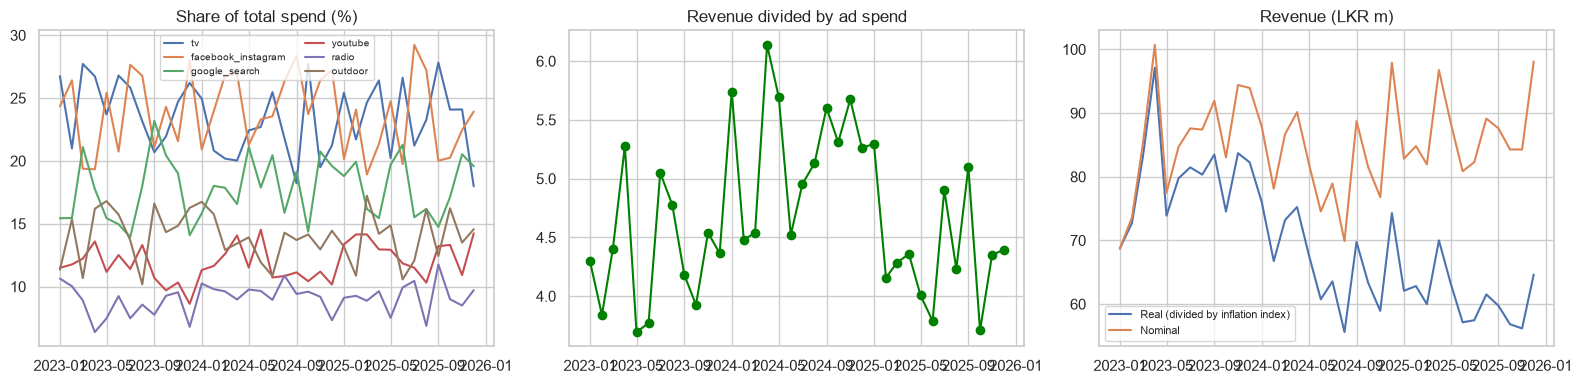

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n in CHANNEL_NAMES.values():
    ax[0].plot(feats["month"], feats[f"{n}_share"] * 100, label=n)
ax[0].set(title="Share of total spend (%)")
ax[0].legend(fontsize=7, ncol=2)
ax[1].plot(feats["month"], feats["roas_blended"], marker="o", color="green")
ax[1].set(title="Revenue divided by ad spend")
ax[2].plot(feats["month"], feats["revenue_real_lkr"] / 1e6, label="Real (divided by inflation index)")
ax[2].plot(feats["month"], feats["sales_revenue_lkr"] / 1e6, label="Nominal")
ax[2].set(title="Revenue (LKR m)")
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG + "05_01_engineered_features.png", dpi=150, bbox_inches="tight")
plt.show()

## Chronological split

A random split would let the model learn from months that come after the ones it is tested on. The last 6 months are therefore held out as the test set and everything before is training data. Inside the training set, four walk-forward folds are defined for tuning: each fold trains on all earlier months and validates on the next 3.

In [6]:
train, test = chronological_split(feats)
folds = expanding_window_folds(len(train))
info = split_info(train, test, folds)
print(pd.DataFrame([{"set": "train", "rows": info["train_rows"], "from": info["train_start"], "to": info["train_end"]},
                    {"set": "test", "rows": info["test_rows"], "from": info["test_start"], "to": info["test_end"]}]).to_string(index=False))
print()
print(pd.DataFrame(info["walk_forward_folds"]).to_string(index=False))

  set  rows       from         to
train    30 2023-01-01 2025-06-01
 test     6 2025-07-01 2025-12-01

 fold  train_rows  train_end validation_start validation_end
    1          18 2024-06-01       2024-07-01     2024-09-01
    2          21 2024-09-01       2024-10-01     2024-12-01
    3          24 2024-12-01       2025-01-01     2025-03-01
    4          27 2025-03-01       2025-04-01     2025-06-01


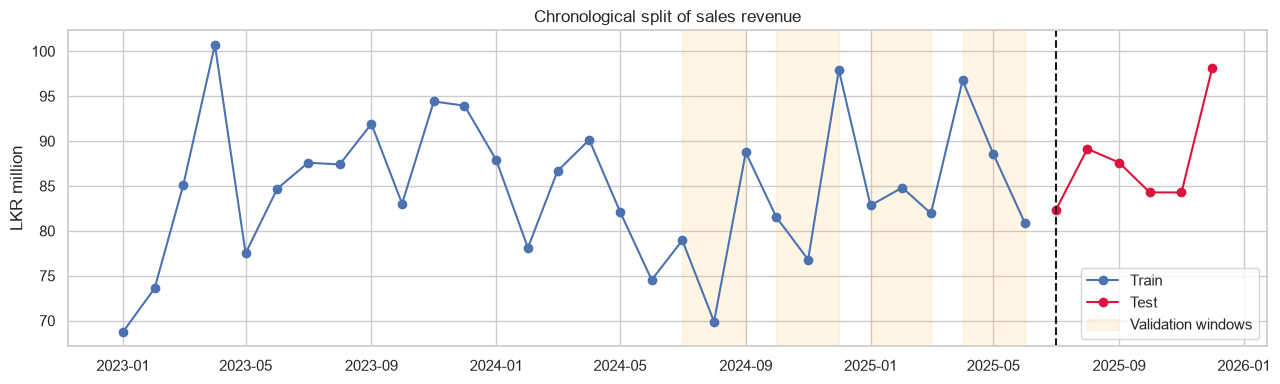

In [7]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train["month"], train["sales_revenue_lkr"] / 1e6, marker="o", label="Train")
ax.plot(test["month"], test["sales_revenue_lkr"] / 1e6, marker="o", color="crimson", label="Test")
ax.axvline(test["month"].min(), ls="--", c="k")
for i, (a, b) in enumerate(folds):
    ax.axvspan(train.month.iloc[b[0]], train.month.iloc[b[-1]], alpha=.10, color="orange",
               label="Validation windows" if i == 0 else None)
ax.set(title="Chronological split of sales revenue", ylabel="LKR million")
ax.legend()
plt.tight_layout()
plt.savefig(FIG + "05_02_train_test_split.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Compare the two periods to see what the model will have to extrapolate to.
cols = ["sales_revenue_lkr", "total_ad_spend_lkr", "promotion_discount_pct", "seasonal_demand_index",
        "inflation_proxy_index", "lkr_usd_exchange_rate"]
shift = pd.DataFrame({"train_mean": train[cols].mean(), "test_mean": test[cols].mean()})
shift["change_pct"] = (shift.test_mean / shift.train_mean - 1) * 100
shift

,train_mean,test_mean,change_pct
sales_revenue_lkr,"84,587,359.367","87,614,867.833",3.579
total_ad_spend_lkr,"18,309,662.200","19,908,443.000",8.732
promotion_discount_pct,11.768,10.987,-6.639
seasonal_demand_index,1.047,1.047,0.000
inflation_proxy_index,1.197,1.475,23.217
lkr_usd_exchange_rate,333.982,344.128,3.038


The test period (July to December 2025) has an inflation index 23% higher than the training period and contains the December peak. A model that relies on the trending variables will have to predict outside the range it was trained on, so a single trend term and a regularised model are safer.

## Checks on the features and the split

In [9]:
checks = validate_features(feats, train, test)
result = pd.DataFrame(checks).T
result["passed"] = result["passed"].map({True: "pass", False: "FAIL"})
print("Passed:", sum(c["passed"] for c in checks.values()), "of", len(checks))
result

Passed: 8 of 8


,passed,detail
channel_shares_sum_to_one,pass,
lags_use_earlier_months_only,pass,
flags_are_binary,pass,
no_infinite_values,pass,
missing_values_only_where_expected,pass,"spend_rolling3_mean, tv_spend_lag1, facebook_i..."
train_before_test,pass,
train_and_test_cover_all_rows,pass,
train_test_no_shared_months,pass,


## Saving the datasets and the feature documentation

In [10]:
# add the feature checks to the data quality summary written in notebook 03
import json
with open("../reports/data_quality_summary.json", encoding="utf-8") as f:
    summary = json.load(f)
summary["feature_checks_passed"] = int(sum(c["passed"] for c in checks.values()))
summary["feature_checks_total"] = len(checks)
summary["feature_checks"] = checks
with open("../reports/data_quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print("Feature checks added to data_quality_summary.json")

Feature checks added to data_quality_summary.json


In [12]:
import json
feats.to_csv("../data/processed/mmm_analysis_ready.csv", index=False)
train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)
with open("../data/processed/split_info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, indent=2)
print("Saved mmm_analysis_ready.csv", feats.shape, "| train.csv", train.shape, "| test.csv", test.shape)

doc = write_data_dictionary(feats, "../reports/data_dictionary.md")
print("Wrote reports/data_dictionary.md for", len(doc), "columns")
doc.groupby("modelling_role").size().sort_values(ascending=False).to_frame("n_columns")

Saved mmm_analysis_ready.csv (36, 66) | train.csv (30, 66) | test.csv (6, 66)
Wrote reports/data_dictionary.md for 66 columns


,n_columns
modelling_role,
control,9
"media, lag 2",6
diagnostic only,6
"media mix, drop one share if all are used",6
"media, transformed",6
media,6
"media, lag 1",6
time control,5
exclude: built from the target,4
